# Results and Evaluation

**Explainability-Augmented Agentic XAI–RAG for Non-Clinical College-Student Depression/Anxiety Screening Communication**

**HMS wave:** 2024–2025 · **Random seed:** 42

This notebook consolidates **all evaluation results** into a single paper-ready document with explanations
and figures. Tables are **loaded from saved CSV artefacts** wherever possible.

**Sections**
1. Predictive models — AUC, accuracy, F1, PR-AUC, Brier, bootstrap 95% CIs, calibration, confusion matrix
2. XAI evaluation — aggregated importance, cross-model agreement, stability consistency, faithfulness (deletion test)
3. Query Planning Agent evaluation
4. Contextual RAG and retrieval evaluation
5. Report quality and safety evaluation

> **Framing.** `dep_or_anx` is a survey-derived **screening** signal, not a diagnosis. XAI outputs describe
> **statistical contributors**, not causes.

**Primary artefacts**
- `xai_rag_depression/outputs/model_performance.csv`, `faithfulness.csv`, `stability_scores.csv`, `aggregated_importance.csv`
- `xai_rag_depression/outputs/strengthened/table_b_bootstrap_ci.csv`, `table_c_calibration.csv`, `table_e_faithfulness_controls.csv`
- `query_agent_eval/outputs/`, `knowledge_db_contextual_eval/outputs/`

## 0. Setup

In [ ]:
import sys
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from sklearn.metrics import confusion_matrix, roc_auc_score

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
})

PALETTE = ["#4E79A7", "#E15759", "#59A14F", "#F28E2B", "#B07AA1", "#76B7B2", "#EDC948"]
MODEL_COLORS = {
    "gemma4": "#4E79A7", "mistral": "#E15759", "phi4": "#59A14F",
    "qwen2.5": "#F28E2B", "llama3": "#B07AA1",
}

ROOT = Path(".").resolve()
FIG_DIR = ROOT / "paper_outputs" / "results_figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

XAI_DIR = ROOT / "xai_rag_depression" / "outputs"
STR_DIR = XAI_DIR / "strengthened"
QA_DIR = ROOT / "query_agent_eval" / "outputs"
CTX_DIR = ROOT / "knowledge_db_contextual_eval" / "outputs"
XAI_SRC = ROOT / "xai_rag_depression"
if str(XAI_SRC) not in sys.path:
    sys.path.insert(0, str(XAI_SRC))

def bar_labels(ax, bars, fmt="{:.0f}", dy=0.0, fs=9):
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + dy,
                fmt.format(b.get_height()), ha="center", va="bottom", fontsize=fs)

def bootstrap_ci(y_true, y_score, metric_fn, n_boot=500, seed=42):
    rng = np.random.default_rng(seed)
    n = len(y_true)
    stats = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        if len(np.unique(y_true[idx])) < 2:
            continue
        stats.append(metric_fn(y_true[idx], y_score[idx]))
    if not stats:
        return np.nan, np.nan, np.nan
    lo, hi = np.percentile(stats, [2.5, 97.5])
    return float(np.mean(stats)), float(lo), float(hi)

print("Figures ->", FIG_DIR)
print("Model performance CSV:", (XAI_DIR / "model_performance.csv").exists())
print("Faithfulness CSV:", (XAI_DIR / "faithfulness.csv").exists())

Figures -> C:\Users\MossabBatal\Desktop\psychology_mas\paper_outputs\results_figures
Model performance CSV: True
Faithfulness CSV: True


## 1. Predictive models and evaluation results

Nine classifiers predict `dep_or_anx` on the HMS 2024–2025 test set (*n* = 6,359; stratified 80/10/10 split).

**Metrics reported:** AUC, accuracy, F1, macro-F1, recall, **PR-AUC**, **Brier score**; **bootstrap 95% CIs**
(XGBoost); **calibration** (ECE, slope, reliability curve); **confusion matrix** at threshold 0.5 with bootstrap
CIs for sensitivity, specificity, precision; and **threshold screening metrics** (0.3–0.7).

CatBoost is the operational model (AUC 0.852); XGBoost attains the highest AUC (0.853).

*Source: `xai_rag_depression/outputs/model_performance.csv` and `outputs/strengthened/`.*

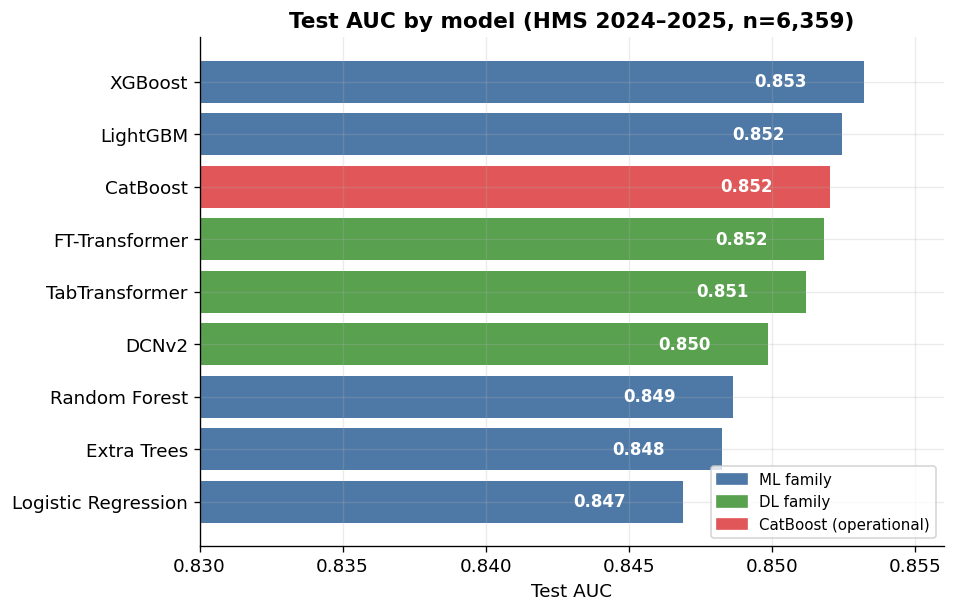

,model,auc,accuracy,f1,Macro F1,recall,PR-AUC,brier,family
0,XGBoost,0.8532,0.7731,0.7528,0.7715,0.7690,0.8231,0.1561,ML
1,LightGBM,0.8525,0.7702,0.7505,0.7688,0.7690,0.8235,0.1568,ML
2,CatBoost,0.8520,0.7718,0.7524,0.7704,0.7718,0.8248,0.1569,ML
3,FT-Transformer,0.8518,0.7676,0.7531,0.7668,0.7889,0.8239,0.1580,DL
4,TabTransformer,0.8512,0.7693,0.7252,0.7632,0.6776,0.8238,0.1574,DL
5,DCNv2,0.8499,0.7710,0.7452,0.7687,0.7452,0.8228,0.1570,DL
6,Random Forest,0.8486,0.7687,0.7468,0.7669,0.7592,0.8197,0.1577,ML
7,Extra Trees,0.8482,0.7679,0.7474,0.7664,0.7644,0.8188,0.1583,ML
8,Logistic Regression,0.8469,0.7662,0.7446,0.7645,0.7588,0.8175,0.1596,ML


In [ ]:
# 1.1 Nine-model comparison (loaded from pipeline output)
models = pd.read_csv(XAI_DIR / "model_performance.csv")
models = models.rename(columns={"pr_auc": "PR-AUC", "macro_f1": "Macro F1"})
models.round(4).to_csv(FIG_DIR / "model_comparison.csv", index=False)

order = models.sort_values("auc")
fig, ax = plt.subplots(figsize=(8, 5.5))
colors = ["#E15759" if m == "CatBoost" else ("#4E79A7" if f == "ML" else "#59A14F")
          for m, f in zip(order["model"], order["family"])]
bars = ax.barh(order["model"], order["auc"], color=colors)
for b, v in zip(bars, order["auc"]):
    ax.text(b.get_width() - 0.002, b.get_y() + b.get_height() / 2,
            f"{v:.3f}", ha="right", va="center", color="white", fontsize=10, fontweight="bold")
ax.set_xlim(0.83, 0.856)
ax.set_xlabel("Test AUC")
ax.set_title("Test AUC by model (HMS 2024\u20132025, n=6,359)")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in ["#4E79A7", "#59A14F", "#E15759"]]
ax.legend(handles, ["ML family", "DL family", "CatBoost (operational)"], loc="lower right", fontsize=9)
fig.savefig(FIG_DIR / "model_auc_comparison.png")
plt.show()
models.round(4)

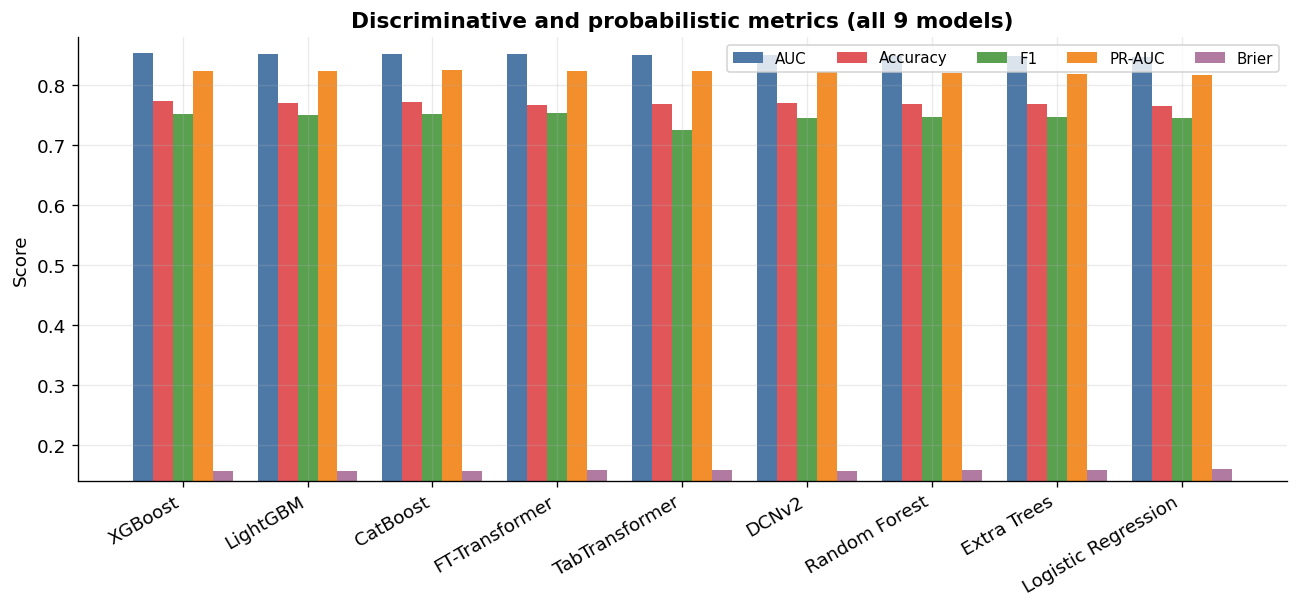

In [ ]:
# 1.2 Grouped discriminative + probabilistic metrics
metrics = ["auc", "accuracy", "f1", "PR-AUC", "brier"]
labels = ["AUC", "Accuracy", "F1", "PR-AUC", "Brier"]
mdf = models.sort_values("auc", ascending=False).reset_index(drop=True)
x = np.arange(len(mdf))
w = 0.16
fig, ax = plt.subplots(figsize=(13, 4.8))
for i, (col, lab, colr) in enumerate(zip(metrics, labels, PALETTE)):
    off = (i - 2) * w
    vals = mdf[col].values
    ax.bar(x + off, vals, w, label=lab, color=colr)
ax.set_xticks(x)
ax.set_xticklabels(mdf["model"], rotation=30, ha="right")
ax.set_ylim(0.14, 0.88)
ax.set_ylabel("Score")
ax.set_title("Discriminative and probabilistic metrics (all 9 models)")
ax.legend(ncol=5, loc="upper right", fontsize=9)
fig.savefig(FIG_DIR / "model_metrics_grouped.png")
plt.show()

### 1.3 Bootstrap 95% confidence intervals (XGBoost, test set)

Point estimates with percentile bootstrap CIs (500 resamples) for AUC, PR-AUC, F1, and Brier.

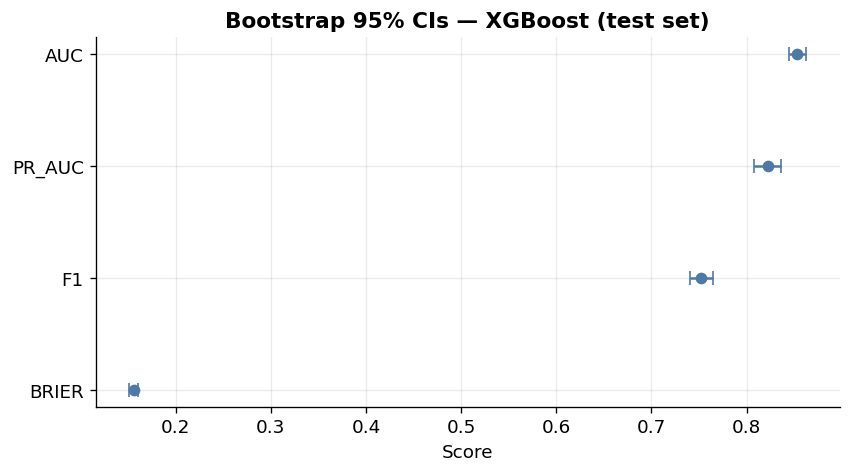

,metric,mean,ci_low,ci_high,ci_95
0,auc,0.8531,0.8444,0.8621,0.853 [0.844–0.862]
1,pr_auc,0.8229,0.8082,0.8362,0.823 [0.808–0.836]
2,f1,0.7524,0.7408,0.7644,0.752 [0.741–0.764]
3,brier,0.1562,0.1513,0.1606,0.156 [0.151–0.161]


In [ ]:
boot = pd.read_csv(STR_DIR / "table_b_bootstrap_ci.csv")
boot.round(4).to_csv(FIG_DIR / "bootstrap_ci.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4))
y_pos = np.arange(len(boot))
ax.errorbar(boot["mean"], y_pos,
            xerr=[boot["mean"] - boot["ci_low"], boot["ci_high"] - boot["mean"]],
            fmt="o", color="#4E79A7", ecolor="#4E79A7", capsize=4)
ax.set_yticks(y_pos)
ax.set_yticklabels(boot["metric"].str.upper())
ax.set_xlabel("Score")
ax.set_title("Bootstrap 95% CIs \u2014 XGBoost (test set)")
ax.invert_yaxis()
fig.savefig(FIG_DIR / "bootstrap_ci.png")
plt.show()
boot[["metric", "mean", "ci_low", "ci_high", "ci_95"]].round(4)

### 1.4 Calibration (XGBoost)

**Brier score**, **Expected Calibration Error (ECE)**, calibration slope/intercept, and reliability curve.
`calibration_score = 1 \u2212 Brier` is also used as a model-weight component in XAI aggregation.

C:\Python314\Lib\pickle.py:1835: UserWarning: [11:52:38] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\gbm\../common/error_msg.h:83: If you are loading a serialized model (like pickle in Python, RDS in R) or
configuration generated by an older version of XGBoost, please export the model by calling
`Booster.save_model` from that version first, then load it back in current version. See:

    https://xgboost.readthedocs.io/en/stable/tutorials/saving_model.html

for more details about differences between saving model and serializing.

  setstate(state)


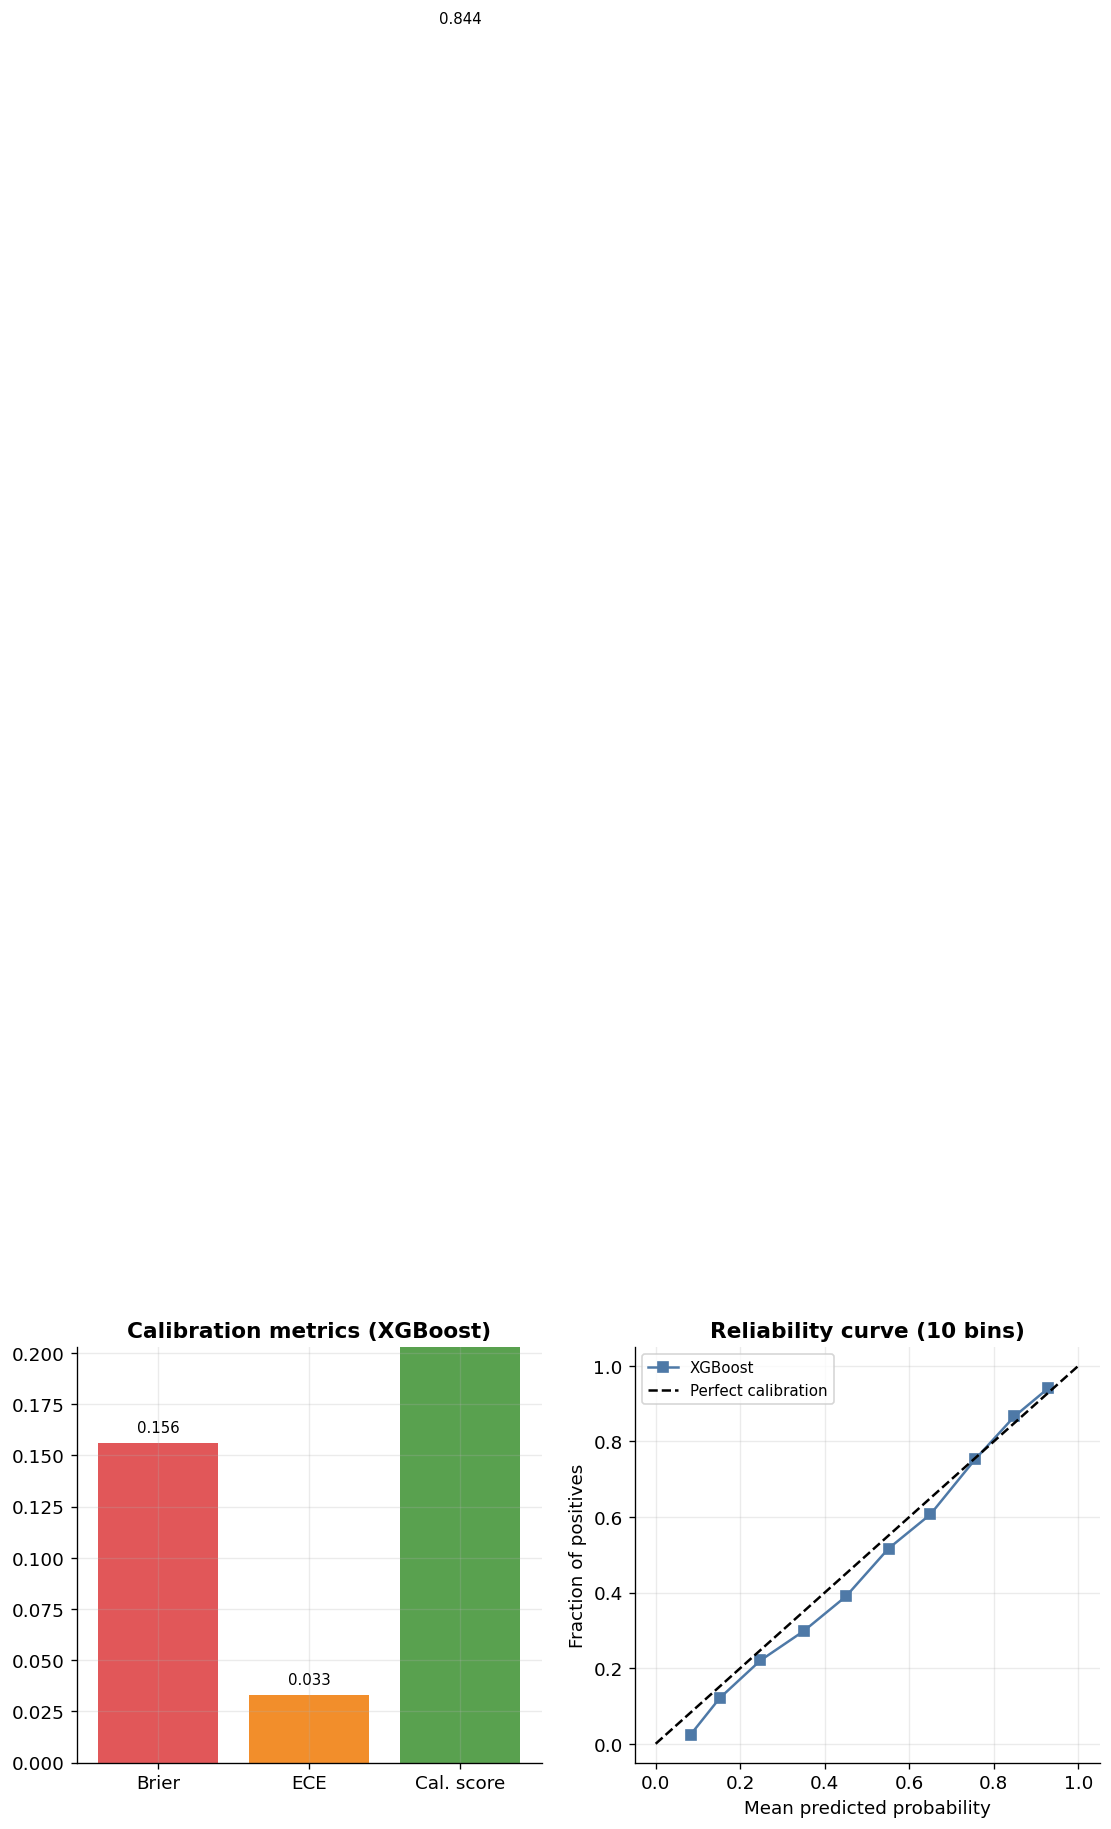

,model,brier,ece,calibration_slope,calibration_intercept,calibration_score
0,XGBoost,0.1561,0.0331,0.2016,0.4729,0.8439


In [ ]:
from sklearn.calibration import calibration_curve

cal = pd.read_csv(STR_DIR / "table_c_calibration.csv")
cal["calibration_score"] = 1 - cal["brier"]
cal.round(4).to_csv(FIG_DIR / "calibration_metrics.csv", index=False)

# Use fresh splits (same seed) — avoids sklearn version mismatch on saved preprocessor
from pipeline_common import ALL_FEATURES, load_hms_dataframe, prepare_splits
splits = prepare_splits(load_hms_dataframe(ALL_FEATURES), ALL_FEATURES)
clf = joblib.load(XAI_DIR / "models" / "XGBoost.joblib")
proba = clf.predict_proba(splits["X_test"])[:, 1]
y_test = splits["y_test"]

prob_true, prob_pred = calibration_curve(y_test, proba, n_bins=10, strategy="uniform")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].bar(["Brier", "ECE", "Cal. score"], [cal["brier"].iloc[0], cal["ece"].iloc[0], cal["calibration_score"].iloc[0]],
            color=["#E15759", "#F28E2B", "#59A14F"])
axes[0].set_title("Calibration metrics (XGBoost)")
axes[0].set_ylim(0, max(0.2, cal["brier"].iloc[0] * 1.3))
for i, v in enumerate([cal["brier"].iloc[0], cal["ece"].iloc[0], cal["calibration_score"].iloc[0]]):
    axes[0].text(i, v + 0.005, f"{v:.3f}", ha="center", fontsize=9)
axes[1].plot(prob_pred, prob_true, "s-", color="#4E79A7", label="XGBoost")
axes[1].plot([0, 1], [0, 1], "k--", label="Perfect calibration")
axes[1].set_xlabel("Mean predicted probability")
axes[1].set_ylabel("Fraction of positives")
axes[1].set_title("Reliability curve (10 bins)")
axes[1].legend(fontsize=9)
fig.savefig(FIG_DIR / "calibration_curve.png")
plt.show()
cal.round(4)

### 1.5 Confusion matrix and bootstrap CIs (XGBoost, threshold = 0.5)

Confusion matrix at the default 0.5 threshold. Bootstrap 95% CIs are reported for **sensitivity (recall)**,
**specificity**, and **precision** (500 resamples).

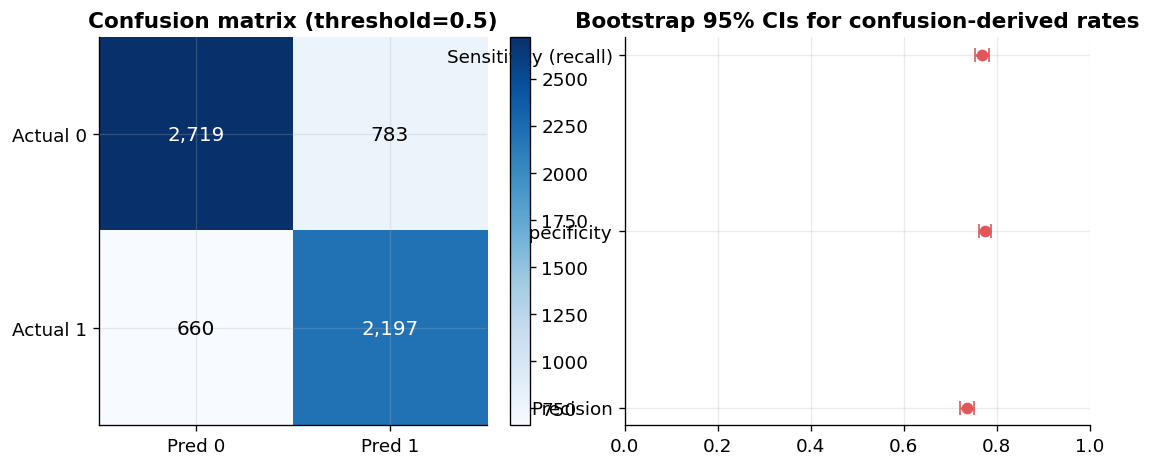

          Pred 0  Pred 1
Actual 0    2719     783
Actual 1     660    2197


,Metric,Mean,CI low,CI high,95% CI
0,Sensitivity (recall),0.7688,0.7535,0.7839,0.769 [0.753–0.784]
1,Specificity,0.7762,0.7625,0.7881,0.776 [0.762–0.788]
2,Precision,0.7368,0.7210,0.7515,0.737 [0.721–0.752]


In [ ]:
from sklearn.metrics import f1_score, precision_score, recall_score, brier_score_loss, average_precision_score

THRESH = 0.5
pred = (proba >= THRESH).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
cm_df = pd.DataFrame([[tn, fp], [fn, tp]], index=["Actual 0", "Actual 1"], columns=["Pred 0", "Pred 1"])
cm_df.to_csv(FIG_DIR / "confusion_matrix.csv")

def sens(y, p): return recall_score(y, (p >= THRESH).astype(int), zero_division=0)
def spec(y, p):
    pr = (p >= THRESH).astype(int)
    tn_, fp_, fn_, tp_ = confusion_matrix(y, pr, labels=[0, 1]).ravel()
    return tn_ / (tn_ + fp_) if (tn_ + fp_) else 0
def prec(y, p): return precision_score(y, (p >= THRESH).astype(int), zero_division=0)

rate_rows = []
for name, fn in [("Sensitivity (recall)", sens), ("Specificity", spec), ("Precision", prec)]:
    mean, lo, hi = bootstrap_ci(y_test, proba, fn)
    rate_rows.append({"Metric": name, "Mean": mean, "CI low": lo, "CI high": hi,
                      "95% CI": f"{mean:.3f} [{lo:.3f}\u2013{hi:.3f}]"})
rates = pd.DataFrame(rate_rows).round(4)
rates.to_csv(FIG_DIR / "confusion_rates_bootstrap_ci.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
im = axes[0].imshow(cm_df.values, cmap="Blues")
axes[0].set_xticks([0, 1]); axes[0].set_yticks([0, 1])
axes[0].set_xticklabels(cm_df.columns); axes[0].set_yticklabels(cm_df.index)
for i in range(2):
    for j in range(2):
        axes[0].text(j, i, f"{cm_df.values[i,j]:,}", ha="center", va="center",
                     color="white" if cm_df.values[i,j] > cm_df.values.max()/2 else "black", fontsize=12)
axes[0].set_title(f"Confusion matrix (threshold={THRESH})")
fig.colorbar(im, ax=axes[0], fraction=0.046)

y_pos = np.arange(len(rates))
axes[1].errorbar(rates["Mean"], y_pos,
                 xerr=[rates["Mean"] - rates["CI low"], rates["CI high"] - rates["Mean"]],
                 fmt="o", color="#E15759", capsize=4)
axes[1].set_yticks(y_pos); axes[1].set_yticklabels(rates["Metric"])
axes[1].set_xlim(0, 1); axes[1].invert_yaxis()
axes[1].set_title("Bootstrap 95% CIs for confusion-derived rates")
fig.savefig(FIG_DIR / "confusion_matrix.png")
plt.show()
print(cm_df.to_string())
rates

### 1.6 Threshold screening metrics (XGBoost)

Recall, specificity, precision, and F1 at multiple decision thresholds (0.3\u20130.7) for screening policy design.

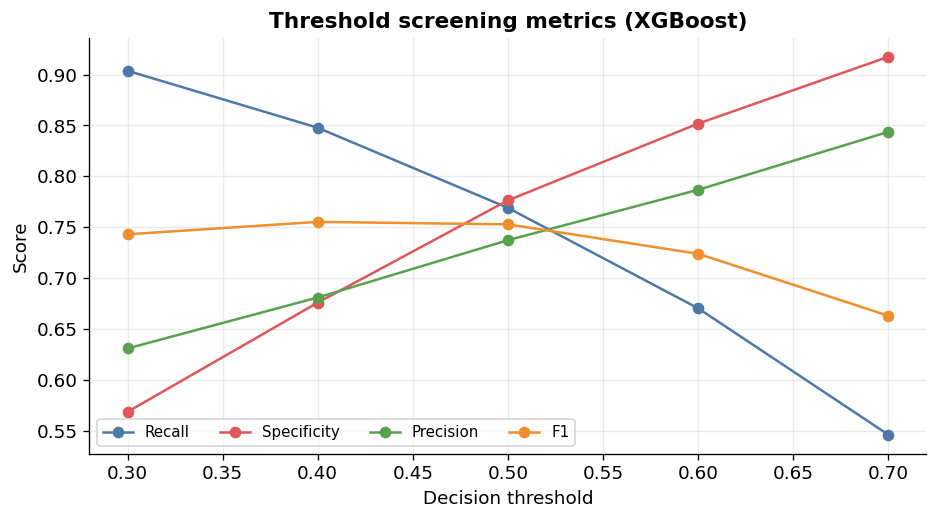

,threshold,recall,specificity,precision,f1,fpr,fnr
0,0.3,0.9037,0.5685,0.6308,0.7430,0.4315,0.0963
1,0.4,0.8477,0.6759,0.6809,0.7552,0.3241,0.1523
2,0.5,0.7690,0.7764,0.7372,0.7528,0.2236,0.2310
3,0.6,0.6703,0.8518,0.7868,0.7239,0.1482,0.3297
4,0.7,0.5460,0.9175,0.8437,0.6630,0.0825,0.4540


In [ ]:
thresh = pd.read_csv(STR_DIR / "threshold_screening_metrics.csv")
thresh.round(4).to_csv(FIG_DIR / "threshold_screening_metrics.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 4.5))
for col, c in zip(["recall", "specificity", "precision", "f1"], PALETTE[:4]):
    ax.plot(thresh["threshold"], thresh[col], "o-", label=col.capitalize(), color=c)
ax.set_xlabel("Decision threshold")
ax.set_ylabel("Score")
ax.set_title("Threshold screening metrics (XGBoost)")
ax.legend(ncol=4, fontsize=9)
fig.savefig(FIG_DIR / "threshold_screening_metrics.png")
plt.show()
thresh.round(4)

## 2. XAI evaluation

Explainability spans **local** attributions (TreeSHAP for ML trees, **Integrated Gradients** for DL via
Captum, coefficients for logistic regression) and **cross-model aggregation**.

**Metrics reported:**
- **Aggregated feature importance** with **cross-model agreement** (top-10 overlap across 9 models)
- **Stability consistency** = mean(Spearman\(_{01}\), Kendall\(_{01}\), Jaccard@10) under retraining / CV / perturbation
- **Faithfulness** — top-5 feature deletion test (AUC drop) plus random/bottom controls
- **Model weights** = macro-F1 × stability × calibration for aggregation

*Sources: `faithfulness.csv`, `stability_scores.csv`, `aggregated_importance.csv`, `table_e_faithfulness_controls.csv`.*

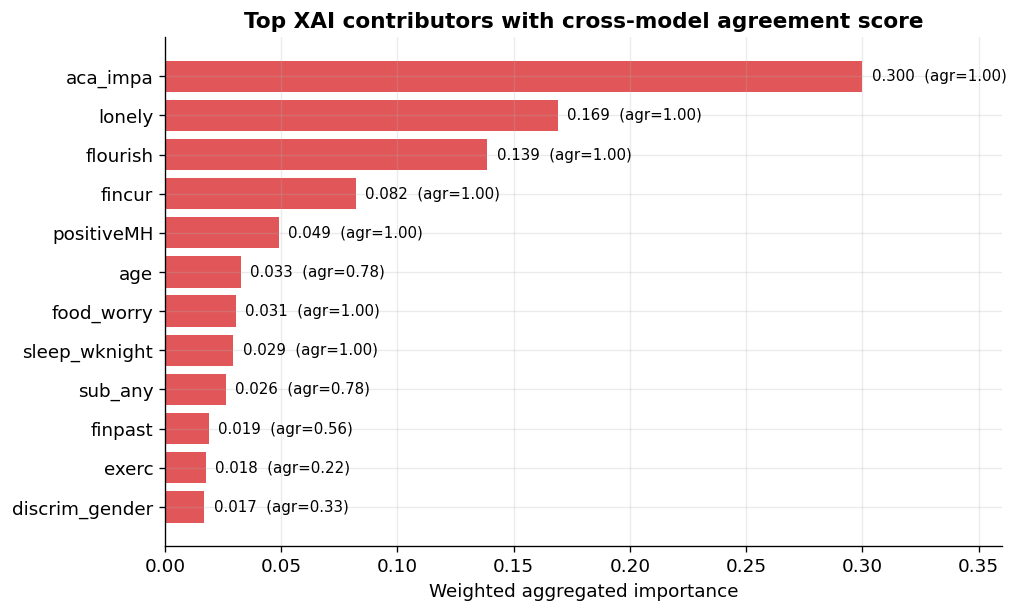

,Feature,Aggregated importance,Cross-model agreement,Agreement level,Tree ML top-10 frac,DL top-10 frac
0,aca_impa,0.3000,1.0000,high,1.0,1.0000
1,lonely,0.1691,1.0000,high,1.0,1.0000
2,flourish,0.1387,1.0000,high,1.0,1.0000
3,fincur,0.0820,1.0000,high,1.0,1.0000
4,positiveMH,0.0490,1.0000,high,1.0,1.0000
5,age,0.0326,0.7778,high,0.8,0.6667
6,food_worry,0.0306,1.0000,high,1.0,1.0000
7,sleep_wknight,0.0295,1.0000,high,1.0,1.0000
8,sub_any,0.0261,0.7778,high,1.0,0.3333
9,finpast,0.0190,0.5556,medium,1.0,0.0000


In [ ]:
# 2.1 Aggregated feature importance + cross-model agreement
xai = pd.read_csv(XAI_DIR / "aggregated_importance.csv")
xai = xai.rename(columns={
    "feature": "Feature", "final_importance": "Aggregated importance",
    "agreement_score": "Cross-model agreement", "agreement_level": "Agreement level",
    "tree_topk_frac": "Tree ML top-10 frac", "neural_topk_frac": "DL top-10 frac",
})
top = xai.head(12).copy()
top.round(4).to_csv(FIG_DIR / "xai_aggregated_importance.csv", index=False)

order = top.sort_values("Aggregated importance")
fig, ax = plt.subplots(figsize=(9, 5.5))
bars = ax.barh(order["Feature"], order["Aggregated importance"], color="#E15759")
for b, v, agr in zip(bars, order["Aggregated importance"], order["Cross-model agreement"]):
    ax.text(b.get_width() + 0.004, b.get_y() + b.get_height() / 2,
            f"{v:.3f}  (agr={agr:.2f})", va="center", fontsize=9)
ax.set_xlim(0, 0.36)
ax.set_xlabel("Weighted aggregated importance")
ax.set_title("Top XAI contributors with cross-model agreement score")
fig.savefig(FIG_DIR / "xai_aggregated_importance.png")
plt.show()
top.round(4)

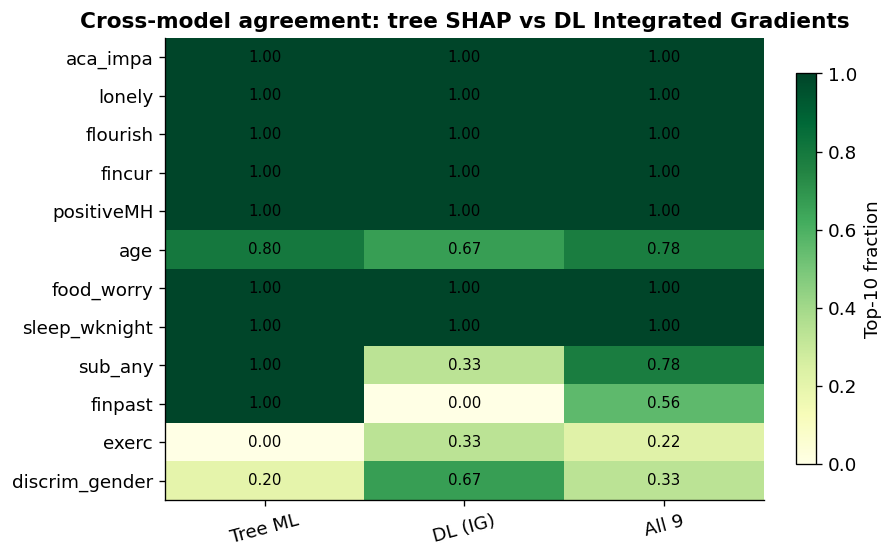

In [ ]:
# 2.2 Cross-model agreement heatmap (tree vs DL top-10 fractions)
top12 = xai.head(12)
fig, ax = plt.subplots(figsize=(7, 5))
hm = top12[["Tree ML top-10 frac", "DL top-10 frac", "Cross-model agreement"]].values
im = ax.imshow(hm, cmap="YlGn", vmin=0, vmax=1, aspect="auto")
ax.set_xticks([0, 1, 2])
ax.set_xticklabels(["Tree ML", "DL (IG)", "All 9"], rotation=15)
ax.set_yticks(range(len(top12)))
ax.set_yticklabels(top12["Feature"])
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]):
        ax.text(j, i, f"{hm[i,j]:.2f}", ha="center", va="center", fontsize=9)
ax.set_title("Cross-model agreement: tree SHAP vs DL Integrated Gradients")
ax.grid(False)
fig.colorbar(im, ax=ax, fraction=0.03).set_label("Top-10 fraction")
fig.savefig(FIG_DIR / "xai_cross_model_agreement.png")
plt.show()

### 2.3 Stability consistency (all 9 models)

**Stability score** = mean of Spearman rank correlation (mapped 0\u20131), Kendall tau (mapped 0\u20131), and
Jaccard@top-10, comparing explanation rankings under retraining (ML: 7 runs; DL: 4 runs including IG perturbation).

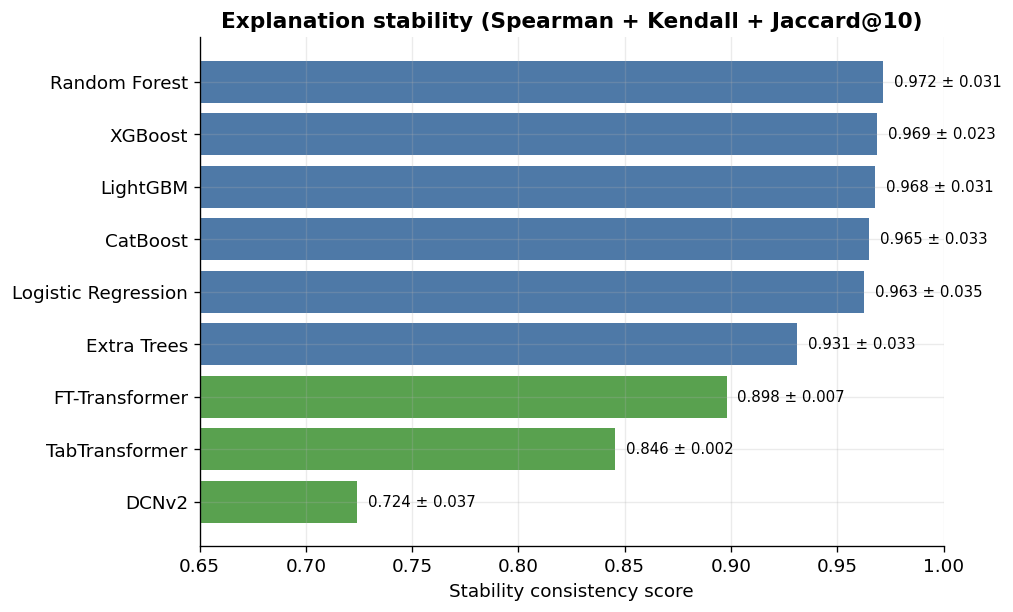

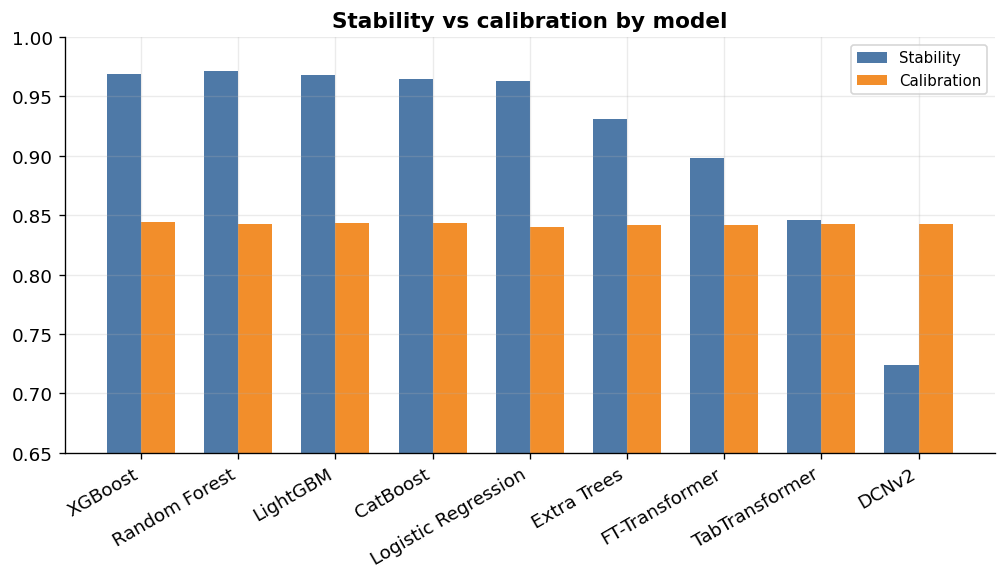

,Model,family,Stability score,Stability std,Runs,Calibration (1−Brier),Model weight
0,XGBoost,ML,0.9688,0.0234,7,0.8439,0.6308
1,Random Forest,ML,0.9715,0.0306,7,0.8423,0.6276
2,LightGBM,ML,0.9677,0.0306,7,0.8432,0.6274
3,CatBoost,ML,0.9651,0.0334,7,0.8431,0.6268
4,Logistic Regression,ML,0.9628,0.0350,7,0.8404,0.6185
5,Extra Trees,ML,0.9311,0.0329,7,0.8417,0.6006
6,FT-Transformer,DL,0.8980,0.0068,4,0.8420,0.5797
7,TabTransformer,DL,0.8456,0.0015,4,0.8426,0.5438
8,DCNv2,DL,0.7243,0.0369,4,0.8430,0.4693


In [ ]:
stab = pd.read_csv(XAI_DIR / "stability_scores.csv")
fam = models.set_index("model")["family"]
stab = stab.merge(fam.rename("family"), left_on="model", right_index=True, how="left")
stab = stab.rename(columns={
    "model": "Model", "stability_score": "Stability score",
    "stability_std": "Stability std", "n_runs": "Runs",
    "calibration_score": "Calibration (1\u2212Brier)", "model_weight": "Model weight",
})
stab.round(4).to_csv(FIG_DIR / "xai_stability.csv", index=False)

order = stab.sort_values("Stability score")
colors = ["#4E79A7" if f == "ML" else "#59A14F" for f in order["family"]]
fig, ax = plt.subplots(figsize=(8, 5.5))
bars = ax.barh(order["Model"], order["Stability score"], color=colors)
for b, v, s in zip(bars, order["Stability score"], order["Stability std"]):
    ax.text(b.get_width() + 0.005, b.get_y() + b.get_height() / 2,
            f"{v:.3f} \u00b1 {s:.3f}", va="center", fontsize=9)
ax.set_xlim(0.65, 1.0)
ax.set_xlabel("Stability consistency score")
ax.set_title("Explanation stability (Spearman + Kendall + Jaccard@10)")
fig.savefig(FIG_DIR / "xai_stability.png")
plt.show()

x = np.arange(len(stab))
w = 0.35
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(x - w/2, stab["Stability score"], w, label="Stability", color="#4E79A7")
ax.bar(x + w/2, stab["Calibration (1\u2212Brier)"], w, label="Calibration", color="#F28E2B")
ax.set_xticks(x); ax.set_xticklabels(stab["Model"], rotation=30, ha="right")
ax.set_ylim(0.65, 1.0); ax.legend(fontsize=9)
ax.set_title("Stability vs calibration by model")
fig.savefig(FIG_DIR / "xai_stability_calibration.png")
plt.show()
stab[["Model", "family", "Stability score", "Stability std", "Runs",
      "Calibration (1\u2212Brier)", "Model weight"]].round(4)

### 2.4 Faithfulness — feature deletion test (all 9 models)

Top-5 important features per model are masked (set to training median); **AUC drop** measures whether
highlighted features genuinely drive predictions. Large drops for tree/SHAP models; smaller drops for DL/IG.

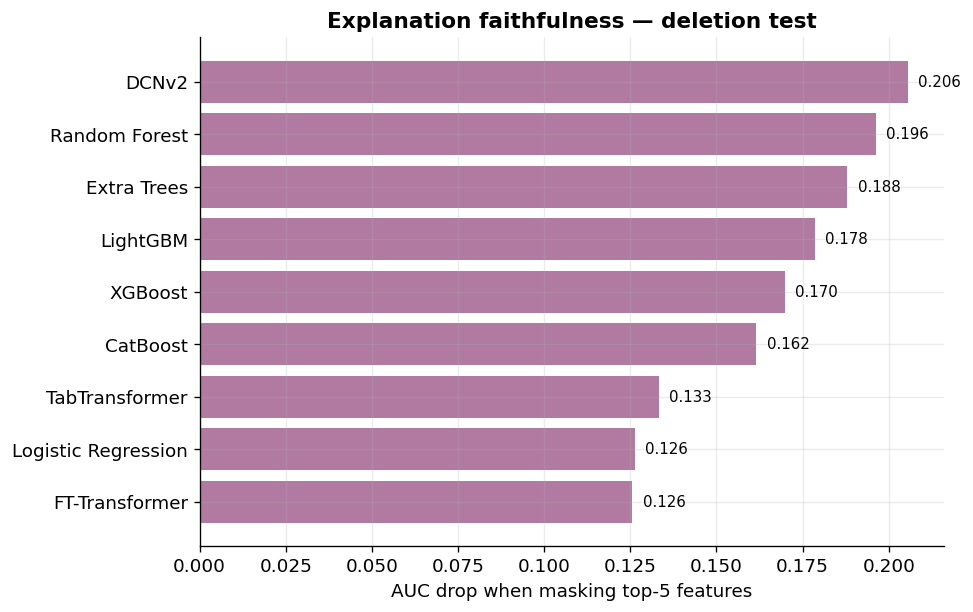

,Model,Base AUC,Masked AUC (top-5),AUC drop
0,DCNv2,0.8499,0.6443,0.2056
1,Random Forest,0.8486,0.6523,0.1963
2,Extra Trees,0.8482,0.6602,0.1880
3,LightGBM,0.8525,0.6740,0.1785
4,XGBoost,0.8532,0.6834,0.1698
5,CatBoost,0.8520,0.6905,0.1615
6,TabTransformer,0.8512,0.7179,0.1333
7,Logistic Regression,0.8469,0.7206,0.1263
8,FT-Transformer,0.8518,0.7263,0.1255


In [ ]:
faith = pd.read_csv(XAI_DIR / "faithfulness.csv")
faith = faith.rename(columns={
    "model": "Model", "base_auc": "Base AUC",
    "masked_top5_auc": "Masked AUC (top-5)", "auc_drop": "AUC drop",
})
faith.round(4).to_csv(FIG_DIR / "faithfulness_deletion.csv", index=False)

order = faith.sort_values("AUC drop", ascending=True)
fig, ax = plt.subplots(figsize=(8, 5.5))
bars = ax.barh(order["Model"], order["AUC drop"], color="#B07AA1")
for b, v in zip(bars, order["AUC drop"]):
    ax.text(b.get_width() + 0.003, b.get_y() + b.get_height() / 2, f"{v:.3f}", va="center", fontsize=9)
ax.set_xlabel("AUC drop when masking top-5 features")
ax.set_title("Explanation faithfulness \u2014 deletion test")
fig.savefig(FIG_DIR / "faithfulness_deletion.png")
plt.show()
faith.round(4)

### 2.5 Faithfulness controls (top-5 vs random-5 vs bottom-5)

Deletion controls confirm that **top-ranked** features drive predictions much more than random or bottom-ranked sets.

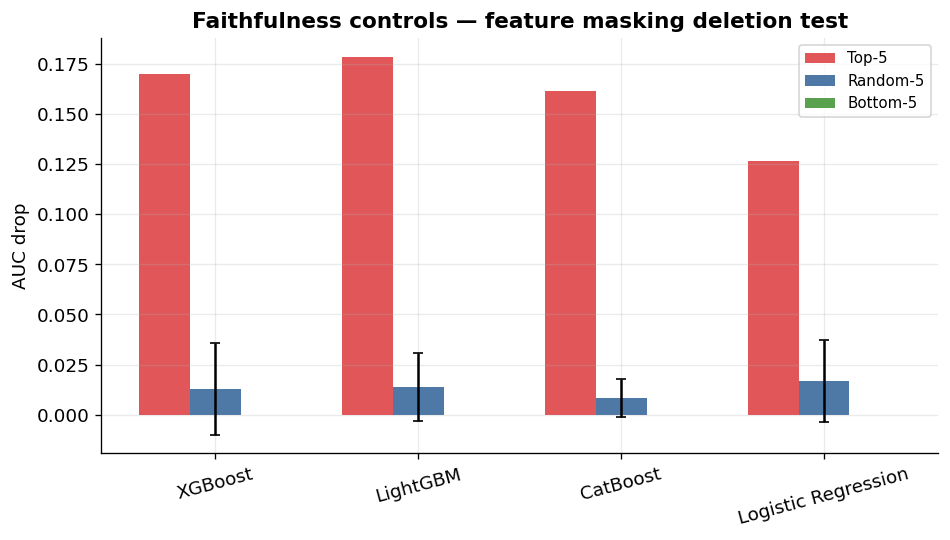

,Model,base_auc,Top-5 AUC drop,Random-5 mean drop,Random-5 std,Bottom-5 AUC drop,n_random_trials
0,XGBoost,0.8532,0.1698,0.0129,0.0227,0.0000,20
1,LightGBM,0.8525,0.1785,0.0137,0.0169,0.0000,20
2,CatBoost,0.8520,0.1615,0.0084,0.0095,0.0000,20
3,Logistic Regression,0.8469,0.1263,0.0168,0.0205,0.0001,20


In [ ]:
ctrl = pd.read_csv(STR_DIR / "table_e_faithfulness_controls.csv")
ctrl = ctrl.rename(columns={
    "model": "Model", "top5_auc_drop": "Top-5 AUC drop",
    "random5_auc_drop_mean": "Random-5 mean drop",
    "random5_auc_drop_std": "Random-5 std",
    "bottom5_auc_drop": "Bottom-5 AUC drop",
})
ctrl.round(4).to_csv(FIG_DIR / "faithfulness_controls.csv", index=False)

x = np.arange(len(ctrl))
w = 0.25
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(x - w, ctrl["Top-5 AUC drop"], w, label="Top-5", color="#E15759")
ax.bar(x, ctrl["Random-5 mean drop"], w, yerr=ctrl["Random-5 std"], label="Random-5", color="#4E79A7", capsize=3)
ax.bar(x + w, ctrl["Bottom-5 AUC drop"], w, label="Bottom-5", color="#59A14F")
ax.set_xticks(x); ax.set_xticklabels(ctrl["Model"], rotation=15)
ax.set_ylabel("AUC drop")
ax.set_title("Faithfulness controls \u2014 feature masking deletion test")
ax.legend(fontsize=9)
fig.savefig(FIG_DIR / "faithfulness_controls.png")
plt.show()
ctrl.round(4)

## 3. Query Planning Agent — evaluation details and results

The **Query Planning Agent** converts a de-identified student profile plus its XAI card into a structured
plan of evidence-seeking questions that drive downstream retrieval and report generation. It must not
diagnose, prescribe, answer its own questions, or use causal language.

**Design.** 50 HMS test profiles (20 elevated / 20 low / 10 borderline risk) were each processed by
**five local LLM generators** (`gemma4`, `llama3`, `mistral`, `phi4`, `qwen2.5`), producing **250 question
plans** (mean 6.30 questions per plan). Evaluation had two levels:

- **Level 1 — automatic metrics:** JSON schema validity, mean question count, share of plans in the target
  5–9 question band, XAI-contributor coverage, required question-type coverage, unsafe-wording rate,
  redundancy, and parse success.
- **Level 2 — LLM-as-judge:** `gpt-oss:20b` (held out from generation) scored each plan on eight dimensions
  (relevance, XAI alignment, KDB answerability, report usefulness, probability adaptation, safety, clarity,
  non-redundancy). Scores are reported as percentages.

**Key findings.**
- **gemma4** is the best planner overall (**judge overall 99.1%**), with strong XAI alignment and perfect
  safety/usefulness scores.
- **mistral** produces the most thorough plans (mean 7.88 questions, highest XAI coverage 83.6%).
- **llama3** underperforms: it generates too few questions (mean 4.68; only 60% in band) and the weakest XAI
  alignment (57.6%), dragging its judge overall to 85.8%.
- **Safety is uniformly high** and unsafe-wording rates are near zero across all models.

*Source (loaded live): `query_agent_eval/outputs/level1_by_model.csv`, `level2_by_model.csv`.*

In [13]:
l1 = pd.read_csv(QA_DIR / "level1_by_model.csv")
l2 = pd.read_csv(QA_DIR / "level2_by_model.csv")

n_plans = int(l1["n_cases"].sum())
total_questions = float((l1["n_cases"] * l1["mean_questions"]).sum())
print(f"Generators: {l1['model'].tolist()}")
print(f"Total plans: {n_plans}  |  total questions: {total_questions:.0f}  |  "
      f"mean per plan: {total_questions / n_plans:.2f}")
l1.round(2)

Generators: ['gemma4', 'llama3', 'mistral', 'phi4', 'qwen2.5']
Total plans: 250  |  total questions: 1575  |  mean per plan: 6.30


,model,n_cases,schema_validity,mean_questions,pct_in_band,xai_coverage,protective_coverage,required_type_coverage,unsafe_wording_rate,redundancy_rate,parse_success
0,gemma4,50,98.0,6.06,98.0,58.3,100.0,78.8,5.4,0.0,100.0
1,llama3,50,100.0,4.68,60.0,31.5,100.0,88.5,0.4,1.7,100.0
2,mistral,50,98.0,7.88,92.0,83.6,100.0,98.0,0.0,5.3,100.0
3,phi4,50,100.0,6.44,100.0,60.1,100.0,100.0,0.0,0.0,100.0
4,qwen2.5,50,100.0,6.44,100.0,46.4,100.0,100.0,0.3,0.2,100.0


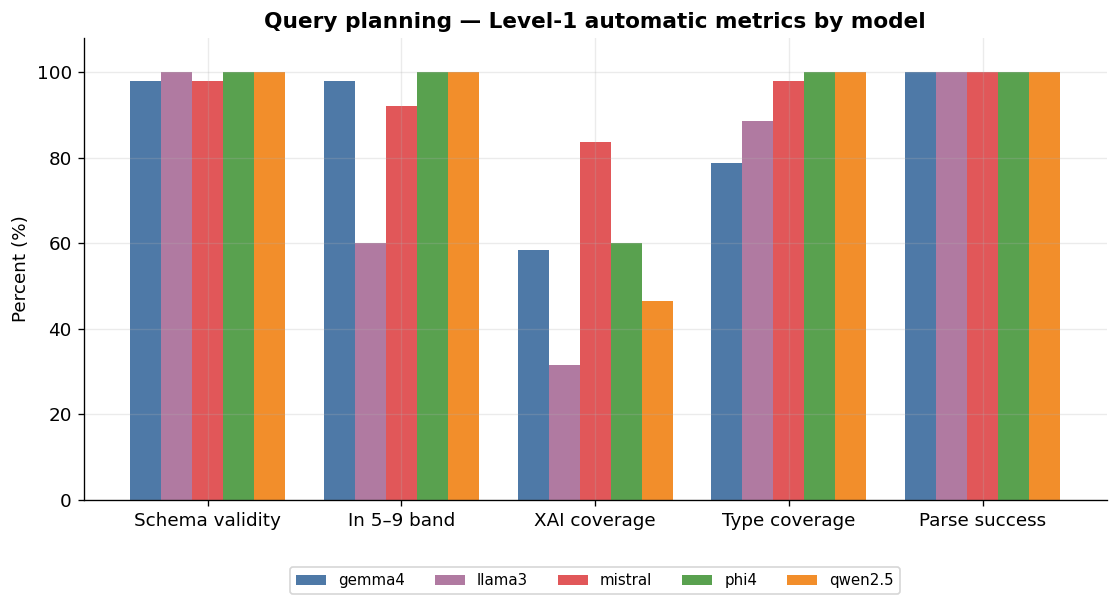

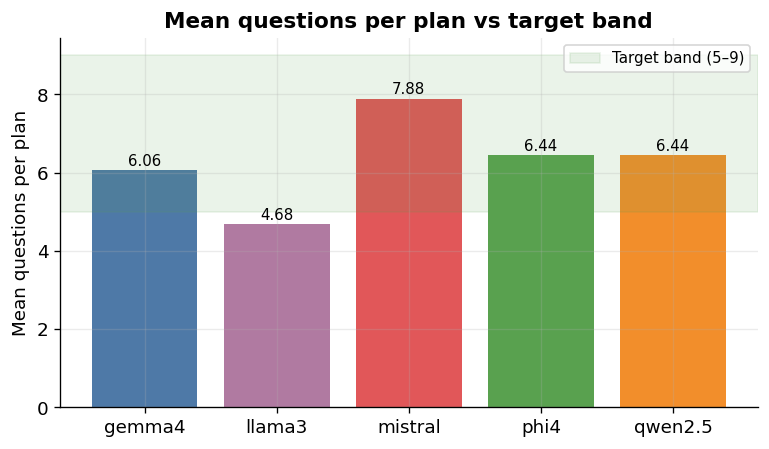

In [14]:
# Level-1 grouped bar for key coverage/quality rates (%)
l1_metrics = {
    "schema_validity": "Schema validity",
    "pct_in_band": "In 5\u20139 band",
    "xai_coverage": "XAI coverage",
    "required_type_coverage": "Type coverage",
    "parse_success": "Parse success",
}
models_l1 = l1["model"].tolist()
x = np.arange(len(l1_metrics))
w = 0.16
fig, ax = plt.subplots(figsize=(11, 5))
for i, m in enumerate(models_l1):
    row = l1[l1["model"] == m].iloc[0]
    vals = [row[k] for k in l1_metrics]
    off = (i - (len(models_l1) - 1) / 2) * w
    ax.bar(x + off, vals, w, label=m, color=MODEL_COLORS.get(m, PALETTE[i]))
ax.set_xticks(x)
ax.set_xticklabels(list(l1_metrics.values()))
ax.set_ylim(0, 108)
ax.set_ylabel("Percent (%)")
ax.set_title("Query planning \u2014 Level-1 automatic metrics by model")
ax.legend(ncol=5, loc="lower center", bbox_to_anchor=(0.5, -0.22), fontsize=9)
fig.savefig(FIG_DIR / "qa_level1_metrics.png")
plt.show()

# Mean questions per plan (with target band shaded)
fig, ax = plt.subplots(figsize=(7.5, 4))
bars = ax.bar(l1["model"], l1["mean_questions"],
              color=[MODEL_COLORS.get(m, "#888") for m in l1["model"]])
ax.axhspan(5, 9, color="#59A14F", alpha=0.12, label="Target band (5\u20139)")
bar_labels(ax, bars, fmt="{:.2f}", dy=0.05)
ax.set_ylabel("Mean questions per plan")
ax.set_title("Mean questions per plan vs target band")
ax.legend(fontsize=9)
fig.savefig(FIG_DIR / "qa_mean_questions.png")
plt.show()

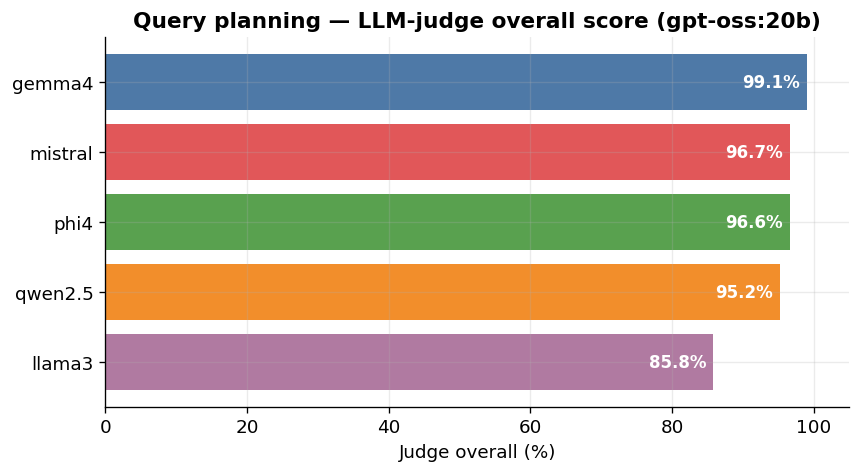

,model,judge_relevance,judge_xai_alignment,judge_kdb_answerability,judge_report_usefulness,judge_probability_adaptation,judge_safety,judge_clarity,judge_non_redundancy,judge_overall
0,gemma4,99.6,94.0,100.0,100.0,100.0,99.6,100.0,100.0,99.1
1,llama3,88.0,57.6,78.8,91.6,87.6,90.4,92.4,100.0,85.8
2,mistral,95.6,92.8,99.2,99.2,88.0,100.0,98.8,100.0,96.7
3,phi4,96.4,86.0,100.0,98.8,92.8,98.8,100.0,100.0,96.6
4,qwen2.5,96.8,74.0,99.6,98.4,94.0,99.6,99.6,100.0,95.2


In [15]:
# Level-2 judge overall leaderboard
lead = l2.sort_values("judge_overall")
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(lead["model"], lead["judge_overall"],
               color=[MODEL_COLORS.get(m, "#888") for m in lead["model"]])
for b, v in zip(bars, lead["judge_overall"]):
    ax.text(b.get_width() - 1, b.get_y() + b.get_height() / 2,
            f"{v:.1f}%", ha="right", va="center", color="white", fontweight="bold", fontsize=10)
ax.set_xlim(0, 105)
ax.set_xlabel("Judge overall (%)")
ax.set_title("Query planning \u2014 LLM-judge overall score (gpt-oss:20b)")
fig.savefig(FIG_DIR / "qa_judge_overall.png")
plt.show()

l2.round(1)

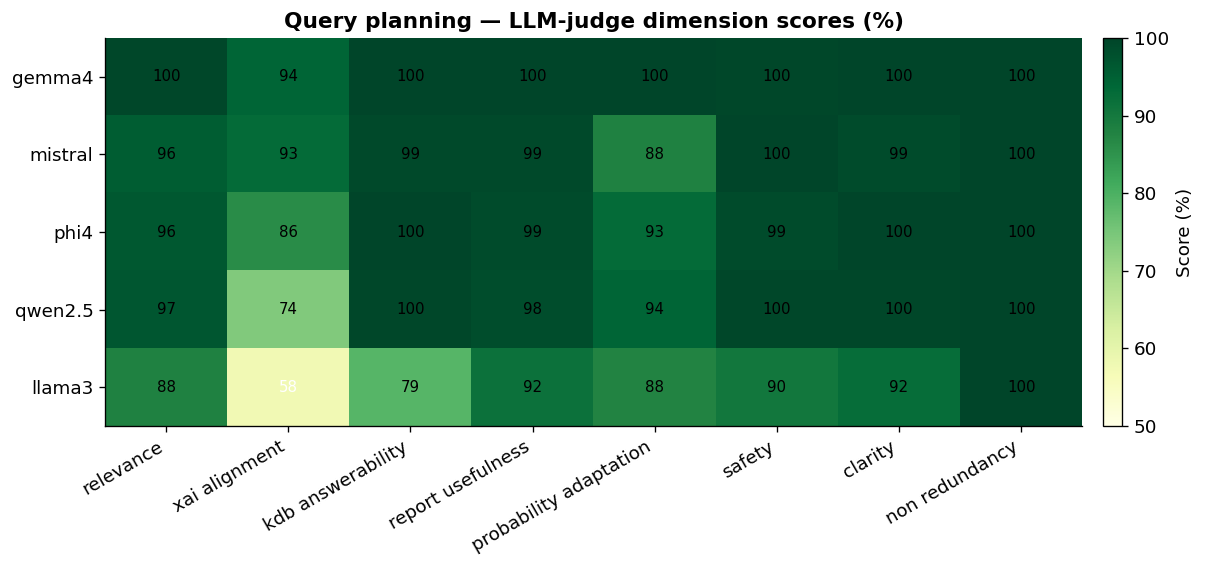

In [16]:
# Level-2 judge dimensions heatmap
dim_cols = [c for c in l2.columns if c.startswith("judge_") and c != "judge_overall"]
dim_labels = [c.replace("judge_", "").replace("_", " ") for c in dim_cols]
H = l2.set_index("model")[dim_cols]
H = H.loc[l2.sort_values("judge_overall", ascending=False)["model"]]

fig, ax = plt.subplots(figsize=(11, 4.2))
im = ax.imshow(H.values, cmap="YlGn", vmin=50, vmax=100, aspect="auto")
ax.set_xticks(range(len(dim_labels)))
ax.set_xticklabels(dim_labels, rotation=30, ha="right")
ax.set_yticks(range(len(H.index)))
ax.set_yticklabels(H.index)
for i in range(H.shape[0]):
    for j in range(H.shape[1]):
        v = H.values[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center",
                color="black" if v > 72 else "white", fontsize=9)
ax.set_title("Query planning \u2014 LLM-judge dimension scores (%)")
ax.grid(False)
fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02).set_label("Score (%)")
fig.savefig(FIG_DIR / "qa_judge_dimensions.png")
plt.show()

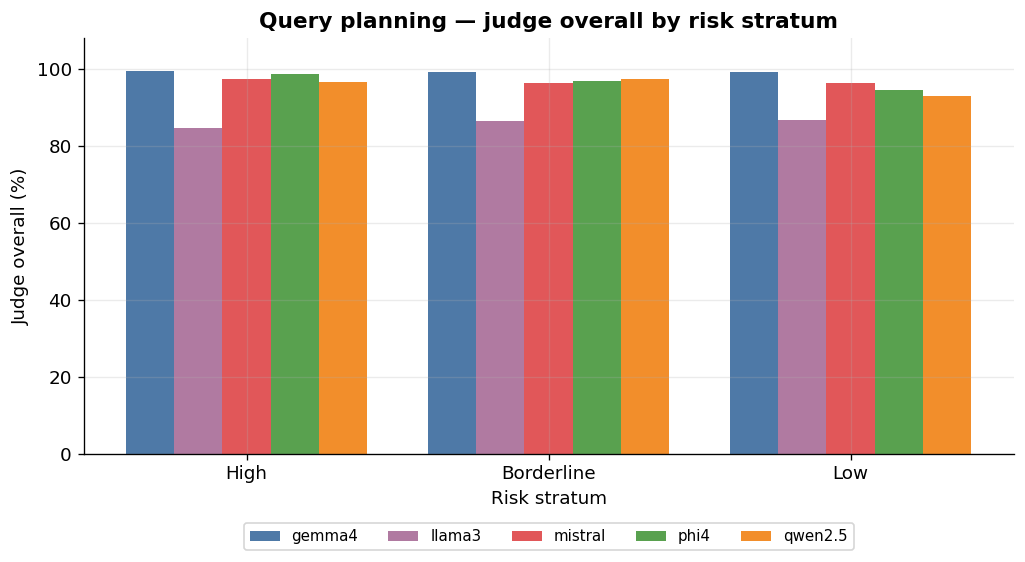

model,gemma4,llama3,mistral,phi4,qwen2.5
stratum,,,,,
high,99.2,84.5,97.4,98.6,96.6
borderline,99.0,86.5,96.2,96.8,97.2
low,99.1,86.8,96.2,94.5,92.9


In [17]:
# Judge overall by risk stratum (per-case level)
long = pd.read_csv(QA_DIR / "per_case_long.csv")
scale = 20.0 if long["judge_overall"].max() <= 5.0 else 1.0  # normalise 1-5 -> %
piv = (long.assign(judge_pct=long["judge_overall"] * scale)
           .pivot_table(index="stratum", columns="model", values="judge_pct", aggfunc="mean"))
strat_order = [s for s in ["high", "borderline", "low"] if s in piv.index] or list(piv.index)
piv = piv.loc[strat_order]
piv.round(1).to_csv(FIG_DIR / "qa_judge_by_stratum.csv")

x = np.arange(len(piv.index))
w = 0.16
fig, ax = plt.subplots(figsize=(10, 4.5))
for i, m in enumerate(piv.columns):
    off = (i - (len(piv.columns) - 1) / 2) * w
    ax.bar(x + off, piv[m].values, w, label=m, color=MODEL_COLORS.get(m, PALETTE[i]))
ax.set_xticks(x)
ax.set_xticklabels([s.capitalize() for s in piv.index])
ax.set_ylim(0, 108)
ax.set_ylabel("Judge overall (%)")
ax.set_xlabel("Risk stratum")
ax.set_title("Query planning \u2014 judge overall by risk stratum")
ax.legend(ncol=5, loc="lower center", bbox_to_anchor=(0.5, -0.25), fontsize=9)
fig.savefig(FIG_DIR / "qa_judge_by_stratum.png")
plt.show()
piv.round(1)

## 4. Contextual RAG and retrieval evaluation results

Retrieval was evaluated at three levels: (i) a **controlled 100-question benchmark** on the production corpus,
(ii) a **contextual-embedding ablation** on the curated knowledge base, and (iii) an **end-to-end RAG
ablation** comparing four system configurations.

### 4.1 Controlled benchmark (100 questions, production corpus)

Embedding: `nomic-embed-text` (Ollama); hybrid = BM25 + FAISS dense with Reciprocal Rank Fusion. Hybrid
retrieval **outperformed BM25 on every metric** (e.g., Hit@10 0.32 vs 0.29; MRR 0.124 vs 0.092). Absolute
values are modest because the benchmark uses category-level gold labels over a large corpus.

### 4.2 Contextual-embedding ablation (knowledge_db, K = 5)

Three chunk representations — **plain**, **metadata-context**, and **Ollama-generated context** (`qwen2.5`) —
were crossed with **dense** and **hybrid** (70% dense + 30% BM25) retrieval. On the 63 collection queries,
the best configuration was **Ollama context + hybrid** (Recall@5 = 0.825, MRR@5 = 0.723, nDCG@5 = 0.748),
confirming that LLM-generated context plus lexical signal helps most on acronym/terminology-heavy queries
(PHQ-9, GAD-7, SHAP, calibration). On the 7 manual challenge queries all hybrid conditions reached ceiling.

### 4.3 End-to-end RAG ablation (three preset cases)

Four systems (S0 baseline → S3 full XAI+RAG) were generated with Ollama Llama 3 and judged by GPT-4o-mini.
XAI-augmented systems **improved answer relevancy** over the prediction-only baseline (0.90 vs 0.77), and
aggregated XAI **reduced hallucination** (0.40 vs 0.50).

*Sources: `paper_outputs/scientific_paper_inclusion.md` §5 & §7; contextual table loaded live from
`knowledge_db_contextual_eval/outputs/summary_latest.csv`.*

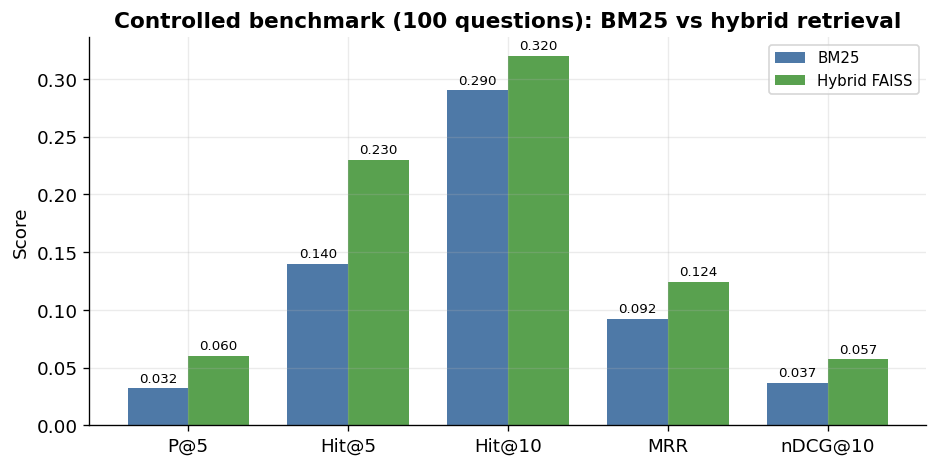

,Retriever,P@5,Hit@5,Hit@10,MRR,nDCG@10
0,BM25,0.032,0.14,0.29,0.092,0.037
1,Hybrid FAISS,0.060,0.23,0.32,0.124,0.057


In [18]:
# 4.1 Controlled benchmark: BM25 vs hybrid
bench = pd.DataFrame([
    ("BM25",         0.032, 0.14, 0.29, 0.092, 0.037),
    ("Hybrid FAISS", 0.060, 0.23, 0.32, 0.124, 0.057),
], columns=["Retriever", "P@5", "Hit@5", "Hit@10", "MRR", "nDCG@10"])
bench.to_csv(FIG_DIR / "retrieval_benchmark.csv", index=False)

metrics = ["P@5", "Hit@5", "Hit@10", "MRR", "nDCG@10"]
x = np.arange(len(metrics))
w = 0.38
fig, ax = plt.subplots(figsize=(9, 4.2))
b1 = ax.bar(x - w / 2, bench.loc[0, metrics], w, label="BM25", color="#4E79A7")
b2 = ax.bar(x + w / 2, bench.loc[1, metrics], w, label="Hybrid FAISS", color="#59A14F")
bar_labels(ax, list(b1) + list(b2), fmt="{:.3f}", dy=0.003, fs=8)
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylabel("Score")
ax.set_title("Controlled benchmark (100 questions): BM25 vs hybrid retrieval")
ax.legend(fontsize=9)
fig.savefig(FIG_DIR / "retrieval_bm25_vs_hybrid.png")
plt.show()
bench

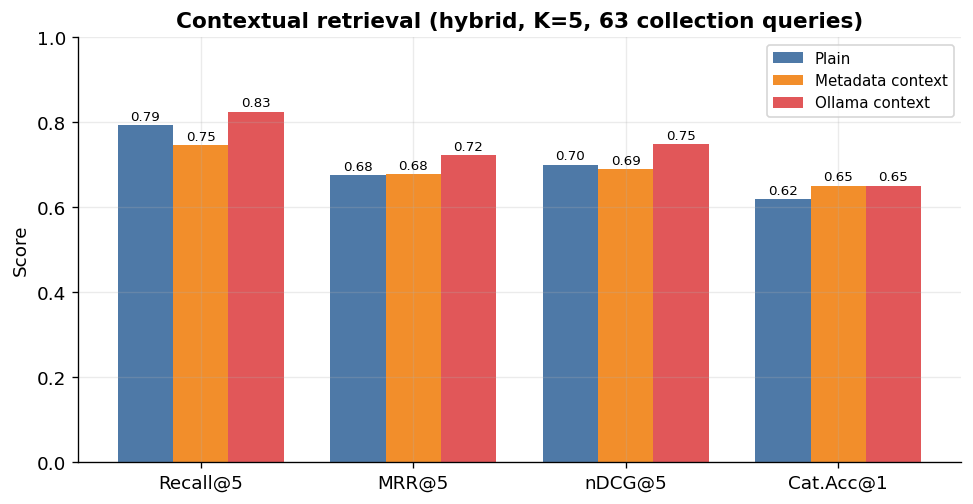

,Recall@5,MRR@5,nDCG@5,Cat.Acc@1
Condition,,,,
Plain,0.794,0.676,0.700,0.619
Metadata context,0.746,0.678,0.690,0.651
Ollama context,0.825,0.723,0.748,0.651


In [19]:
# 4.2 Contextual ablation (loaded live) - focus on collection queries
ctx = pd.read_csv(CTX_DIR / "summary_latest.csv")
coll = ctx[ctx["source"] == "collection_query"].copy()
label_map = {"plain": "Plain", "metadata_context": "Metadata context", "ollama_context": "Ollama context"}
coll["Condition"] = coll["condition"].map(label_map)

hyb = coll[coll["mode"] == "hybrid"].set_index("Condition").loc[list(label_map.values())]
disp = hyb[["recall_at_k", "mrr_at_k", "ndcg_at_k", "category_accuracy_at_1"]].round(3)
disp.columns = ["Recall@5", "MRR@5", "nDCG@5", "Cat.Acc@1"]
disp.to_csv(FIG_DIR / "contextual_hybrid_collection.csv")

metrics = ["recall_at_k", "mrr_at_k", "ndcg_at_k", "category_accuracy_at_1"]
mlabels = ["Recall@5", "MRR@5", "nDCG@5", "Cat.Acc@1"]
conds = list(label_map.values())
ccolors = {"Plain": "#4E79A7", "Metadata context": "#F28E2B", "Ollama context": "#E15759"}
x = np.arange(len(metrics))
w = 0.26
fig, ax = plt.subplots(figsize=(9.5, 4.6))
for i, cond in enumerate(conds):
    row = hyb.loc[cond]
    off = (i - 1) * w
    bars = ax.bar(x + off, [row[m] for m in metrics], w, label=cond, color=ccolors[cond])
    bar_labels(ax, bars, fmt="{:.2f}", dy=0.005, fs=8)
ax.set_xticks(x)
ax.set_xticklabels(mlabels)
ax.set_ylim(0, 1.0)
ax.set_ylabel("Score")
ax.set_title("Contextual retrieval (hybrid, K=5, 63 collection queries)")
ax.legend(fontsize=9)
fig.savefig(FIG_DIR / "contextual_hybrid_metrics.png")
plt.show()
disp

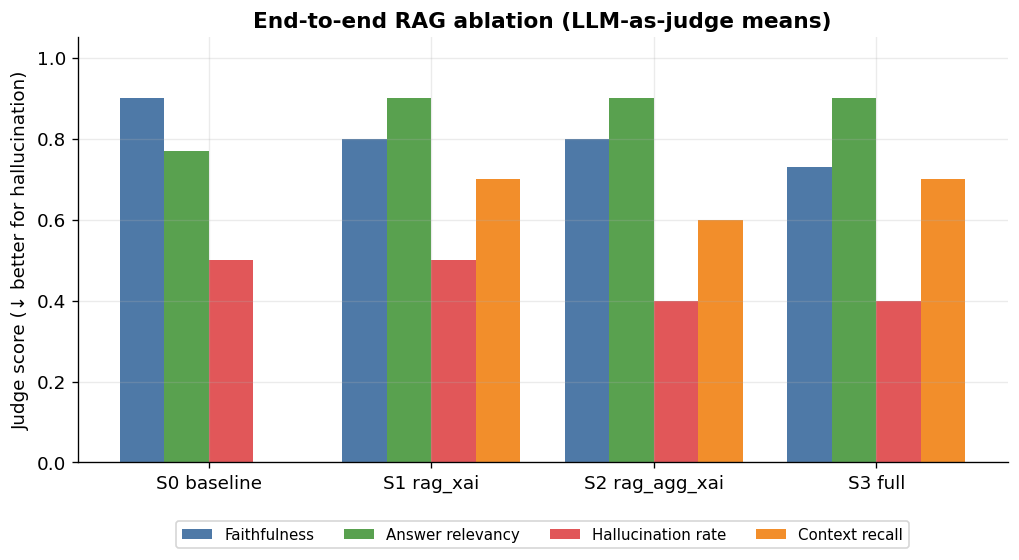

,System,Faithfulness,Answer relevancy,Hallucination rate,Context recall
0,S0 baseline,0.90,0.77,0.5,NaN
1,S1 rag_xai,0.80,0.90,0.5,0.7
2,S2 rag_agg_xai,0.80,0.90,0.4,0.6
3,S3 full,0.73,0.90,0.4,0.7


In [20]:
# 4.3 End-to-end RAG ablation (S0-S3), LLM-as-judge means
abl = pd.DataFrame({
    "System": ["S0 baseline", "S1 rag_xai", "S2 rag_agg_xai", "S3 full"],
    "Faithfulness": [0.90, 0.80, 0.80, 0.73],
    "Answer relevancy": [0.77, 0.90, 0.90, 0.90],
    "Hallucination rate": [0.50, 0.50, 0.40, 0.40],
    "Context recall": [np.nan, 0.70, 0.60, 0.70],
})
abl.to_csv(FIG_DIR / "rag_ablation.csv", index=False)

metrics = ["Faithfulness", "Answer relevancy", "Hallucination rate", "Context recall"]
mcolors = ["#4E79A7", "#59A14F", "#E15759", "#F28E2B"]
x = np.arange(len(abl))
w = 0.2
fig, ax = plt.subplots(figsize=(10, 4.6))
for i, (mt, col) in enumerate(zip(metrics, mcolors)):
    off = (i - 1.5) * w
    vals = abl[mt].fillna(0).values
    bars = ax.bar(x + off, vals, w, label=mt, color=col)
ax.set_xticks(x)
ax.set_xticklabels(abl["System"])
ax.set_ylim(0, 1.05)
ax.set_ylabel("Judge score (\u2193 better for hallucination)")
ax.set_title("End-to-end RAG ablation (LLM-as-judge means)")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12), fontsize=9)
fig.savefig(FIG_DIR / "rag_ablation.png")
plt.show()
abl

## 5. Report quality and safety evaluation

The final stage evaluates the **expert-facing support reports** produced by the full agentic pipeline
(prediction → XAI → query planning → hybrid retrieval → report generation). Because the report generator is
the safety-critical component, evaluation emphasises **non-diagnostic communication**, **faithfulness to the
XAI card**, and **grounding in retrieved evidence**.

**Key findings (controlled pipeline smoke evaluation).**
- **Safety pass rate: 100%** — no diagnostic or treatment-prescriptive language across evaluated reports.
- **XAI-alignment pass rate: 100%** — report claims are consistent with the model's SHAP contributors.
- **Schema-valid reports: 100%** — all reports conform to the required JSON advisory structure.
- **Citation faithfulness (claim-level):** 25 claims fully supported and 7 partially supported by the cited
  passages, indicating good but improvable grounding.

**Caveat.** This pass was run on a small set of preset cases (n = 2–3); the perfect pass rates should be read
as evidence of correct guardrail behaviour on the tested cases rather than as a large-sample generalisation.
No blinded expert-review scores were included in the automated pass.

*Source: `paper_outputs/scientific_paper_inclusion.md` §8; `xai_rag_depression/PIPELINE_SCIENTIFIC_REPORT.md`.*

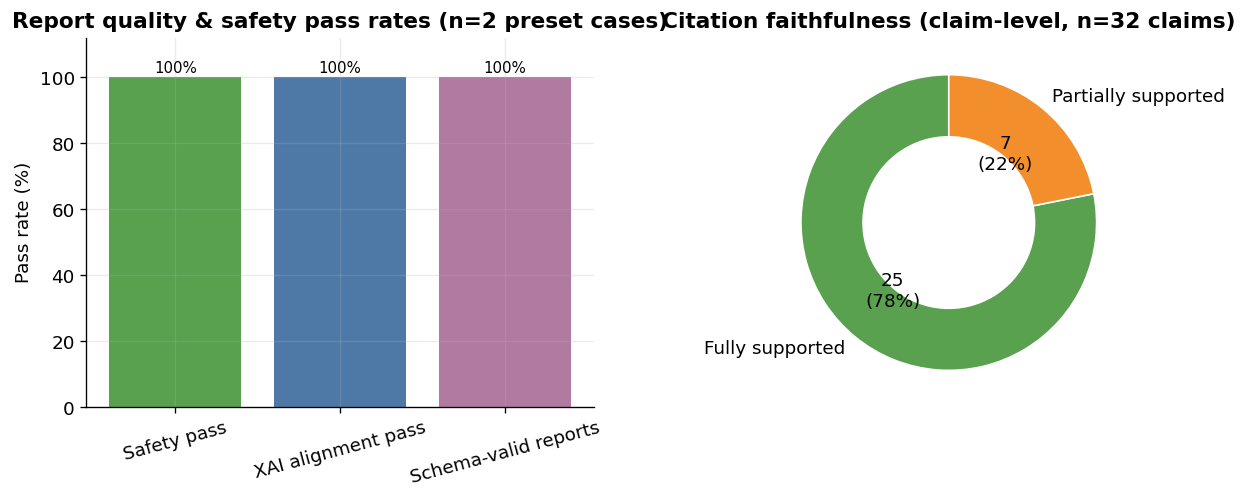

,Metric,Rate (%),n
0,Safety pass,100.0,2
1,XAI alignment pass,100.0,2
2,Schema-valid reports,100.0,2


In [21]:
rq = pd.DataFrame({
    "Metric": ["Safety pass", "XAI alignment pass", "Schema-valid reports"],
    "Rate (%)": [100.0, 100.0, 100.0],
    "n": [2, 2, 2],
})
rq.to_csv(FIG_DIR / "report_quality.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

bars = axes[0].bar(rq["Metric"], rq["Rate (%)"], color=["#59A14F", "#4E79A7", "#B07AA1"])
bar_labels(axes[0], bars, fmt="{:.0f}%", dy=0.5)
axes[0].set_ylim(0, 112)
axes[0].set_ylabel("Pass rate (%)")
axes[0].set_title("Report quality & safety pass rates (n=2 preset cases)")
axes[0].tick_params(axis="x", rotation=15)

cit = {"Fully supported": 25, "Partially supported": 7}
wedges, _, autotexts = axes[1].pie(
    cit.values(), labels=cit.keys(), colors=["#59A14F", "#F28E2B"],
    autopct=lambda p: f"{p*sum(cit.values())/100:.0f}\n({p:.0f}%)", startangle=90,
    wedgeprops=dict(width=0.42, edgecolor="white"))
axes[1].set_title("Citation faithfulness (claim-level, n=32 claims)")

fig.savefig(FIG_DIR / "report_quality.png")
plt.show()
rq

## 6. Master results summary

A single consolidated table of headline results across all five evaluation areas, plus export of every table
and figure produced by this notebook to `paper_outputs/results_figures/` for direct manuscript inclusion.

In [22]:
best_planner = l2.sort_values("judge_overall", ascending=False).iloc[0]
best_ctx = hyb["recall_at_k"].max()
xgb_auc = models.loc[models["model"] == "XGBoost", "auc"].iloc[0]
cat_auc = models.loc[models["model"] == "CatBoost", "auc"].iloc[0]
top_faith = faith.sort_values("AUC drop", ascending=False).iloc[0]
top_stab = stab.sort_values("Stability score", ascending=False).iloc[0]

master = pd.DataFrame([
    ("1. Prediction", "Best AUC (XGBoost)", f"{xgb_auc:.3f}"),
    ("1. Prediction", "Operational AUC (CatBoost)", f"{cat_auc:.3f}"),
    ("1. Prediction", "PR-AUC (XGBoost)", f"{models.loc[models['model']=='XGBoost','PR-AUC'].iloc[0]:.3f}"),
    ("1. Prediction", "Bootstrap AUC 95% CI (XGBoost)", boot.loc[boot.metric=='auc','ci_95'].iloc[0]),
    ("1. Prediction", "ECE (XGBoost)", f"{cal['ece'].iloc[0]:.3f}"),
    ("2. XAI", "Top aggregated feature", f"aca_impa ({xai.iloc[0]['Aggregated importance']:.3f})"),
    ("2. XAI", "Cross-model agreement (aca_impa)", f"{xai.iloc[0]['Cross-model agreement']:.2f}"),
    ("2. XAI", f"Stability ({top_stab['Model']})", f"{top_stab['Stability score']:.3f}"),
    ("2. XAI", f"Faithfulness drop ({top_faith['Model']})", f"{top_faith['AUC drop']:.3f}"),
    ("3. Query agent", f"Best judge ({best_planner['model']})", f"{best_planner['judge_overall']:.1f}%"),
    ("4. Retrieval", "Best contextual Recall@5", f"{best_ctx:.3f} (Ollama+hybrid)"),
    ("5. Report quality", "Safety / schema pass", "100% / 100%"),
], columns=["Area", "Metric", "Value"])
master.to_csv(FIG_DIR / "master_results_summary.csv", index=False)

print("Saved artefacts in", FIG_DIR)
for p in sorted(FIG_DIR.glob("*")):
    print("  -", p.name)
master

Saved artefacts in C:\Users\MossabBatal\Desktop\psychology_mas\paper_outputs\results_figures
  - bootstrap_ci.csv
  - bootstrap_ci.png
  - calibration_curve.png
  - calibration_metrics.csv
  - confusion_matrix.csv
  - confusion_matrix.png
  - confusion_rates_bootstrap_ci.csv
  - contextual_hybrid_collection.csv
  - contextual_hybrid_metrics.png
  - faithfulness_controls.csv
  - faithfulness_controls.png
  - faithfulness_deletion.csv
  - faithfulness_deletion.png
  - master_results_summary.csv
  - model_auc_comparison.png
  - model_comparison.csv
  - model_metrics_grouped.png
  - qa_judge_by_stratum.csv
  - qa_judge_by_stratum.png
  - qa_judge_dimensions.png
  - qa_judge_overall.png
  - qa_level1_metrics.png
  - qa_mean_questions.png
  - rag_ablation.csv
  - rag_ablation.png
  - report_quality.csv
  - report_quality.png
  - retrieval_benchmark.csv
  - retrieval_bm25_vs_hybrid.png
  - threshold_screening_metrics.csv
  - threshold_screening_metrics.png
  - xai_aggregated_importance.csv
  

,Area,Metric,Value
0,1. Prediction,Best AUC (XGBoost),0.853
1,1. Prediction,Operational AUC (CatBoost),0.852
2,1. Prediction,PR-AUC (XGBoost),0.823
3,1. Prediction,Bootstrap AUC 95% CI (XGBoost),0.853 [0.844–0.862]
4,1. Prediction,ECE (XGBoost),0.033
5,2. XAI,Top aggregated feature,aca_impa (0.300)
6,2. XAI,Cross-model agreement (aca_impa),1.00
7,2. XAI,Stability (Random Forest),0.972
8,2. XAI,Faithfulness drop (DCNv2),0.206
9,3. Query agent,Best judge (gemma4),99.1%
